In [1]:
1+1

2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:

df = pd.read_csv("../data/cleaned_telco_churn.csv")

df.shape


(7043, 21)

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:

churn_counts = df["Churn"].value_counts()

churn_counts


Churn
No     5174
Yes    1869
Name: count, dtype: int64

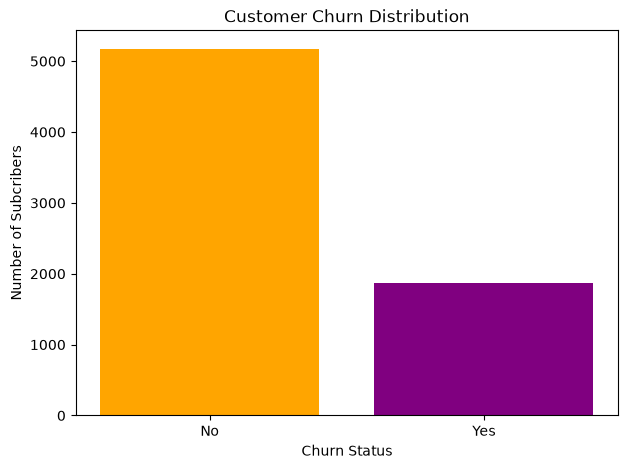

In [7]:
plt.figure(figsize=(7,5))

plt.bar(churn_counts.index, churn_counts.values, color=["orange","purple"])

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Subcribers")

plt.show()

In [8]:
contract_churn = df.groupby("Contract")["Churn"].value_counts()

contract_churn

Contract        Churn
Month-to-month  No       2220
                Yes      1655
One year        No       1307
                Yes       166
Two year        No       1647
                Yes        48
Name: count, dtype: int64

In [14]:

contract_churn_rate = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").sum() / len(x) * 100
)

contract_churn_rate.round(2)


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

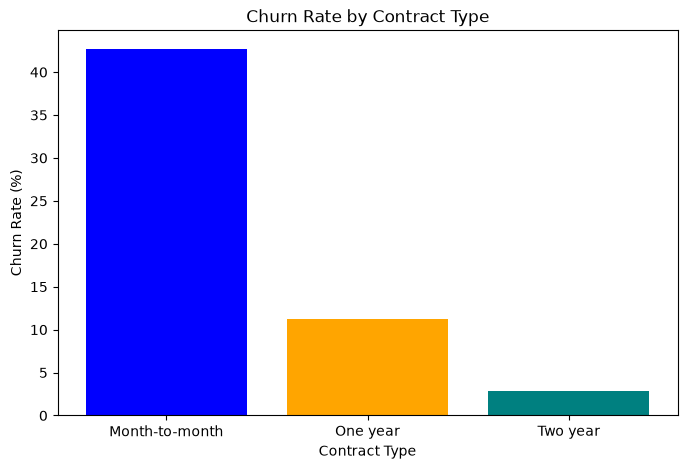

In [15]:
plt.figure(figsize=(8,5))

plt.bar(
    contract_churn_rate.index,
    contract_churn_rate.values,
    color=["blue","orange","teal"]
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show

In [16]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, float("inf")],
    labels=["0-12", "13-24", "25-48", "49+"]
)

df["TenureGroup"].value_counts().sort_index()


TenureGroup
0-12     2186
13-24    1024
25-48    1594
49+      2239
Name: count, dtype: int64

In [17]:

tenure_churn_rate = df.groupby(
    "TenureGroup", observed=True
)["Churn"].apply(
    lambda x: (x == "Yes").sum() / len(x) * 100
)

tenure_churn_rate.round(2)


TenureGroup
0-12     47.44
13-24    28.71
25-48    20.39
49+       9.51
Name: Churn, dtype: float64

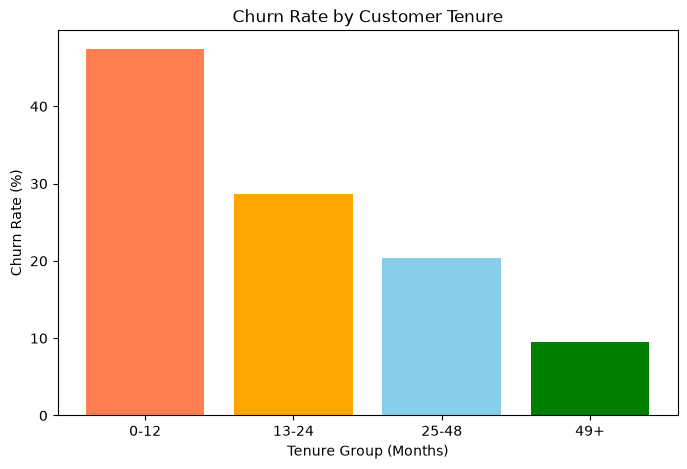

In [18]:

plt.figure(figsize=(8, 5))

plt.bar(
    tenure_churn_rate.index,
    tenure_churn_rate.values,
    color=["coral", "orange", "skyblue", "green"]
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group (Months)")
plt.ylabel("Churn Rate (%)")

plt.show()


In [19]:

monthly_charges = df.groupby("Churn")["MonthlyCharges"].mean()

monthly_charges.round(2)


Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

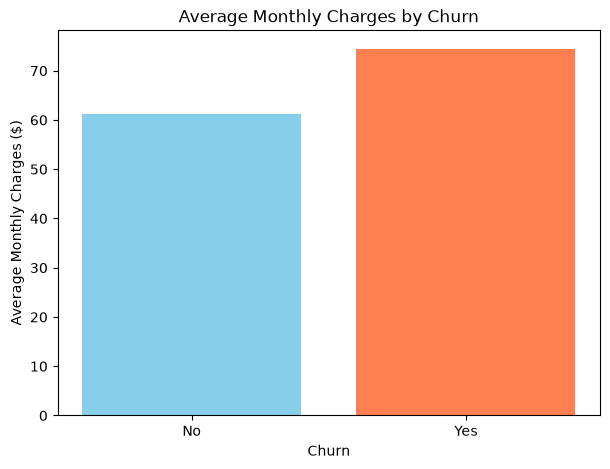

In [25]:

plt.figure(figsize=(7, 5))

plt.bar(
    monthly_charges.index,
    monthly_charges.values,
    color=["skyblue", "coral"]
)

plt.title("Average Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Monthly Charges ($)")

plt.show()


In [26]:

df["ChargesGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 30, 60, 90, float("inf")],
    labels=["0-30", "31-60", "61-90", "90+"]
)

df["ChargesGroup"].value_counts().sort_index()


ChargesGroup
0-30     1653
31-60    1265
61-90    2386
90+      1739
Name: count, dtype: int64

In [27]:

charges_churn_rate = df.groupby(
    "ChargesGroup", observed=True
)["Churn"].apply(
    lambda x: (x == "Yes").sum() / len(x) * 100
)

charges_churn_rate.round(2)


ChargesGroup
0-30      9.80
31-60    25.93
61-90    33.91
90+      32.78
Name: Churn, dtype: float64

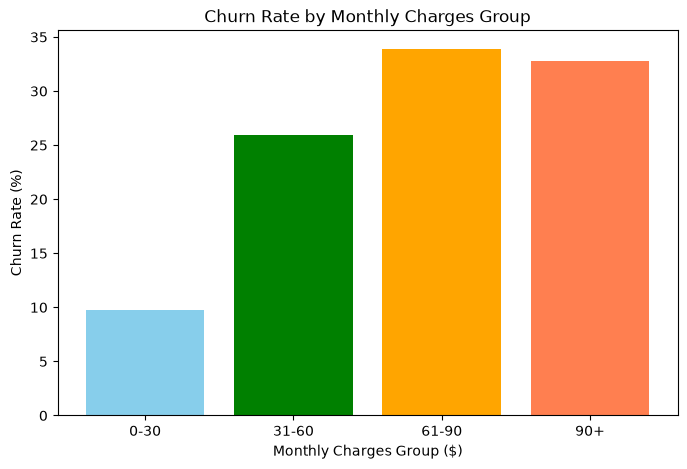

In [28]:

plt.figure(figsize=(8, 5))

plt.bar(
    charges_churn_rate.index,
    charges_churn_rate.values,
    color=["skyblue", "green", "orange", "coral"]
)

plt.title("Churn Rate by Monthly Charges Group")
plt.xlabel("Monthly Charges Group ($)")
plt.ylabel("Churn Rate (%)")

plt.show()


In [29]:

payment_churn = df.groupby("PaymentMethod")["Churn"].value_counts()

payment_churn


PaymentMethod              Churn
Bank transfer (automatic)  No       1286
                           Yes       258
Credit card (automatic)    No       1290
                           Yes       232
Electronic check           No       1294
                           Yes      1071
Mailed check               No       1304
                           Yes       308
Name: count, dtype: int64

In [30]:

payment_churn_rate = df.groupby("PaymentMethod")["Churn"].apply(
    lambda x: (x == "Yes").sum() / len(x) * 100
)

payment_churn_rate.round(2)


PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64

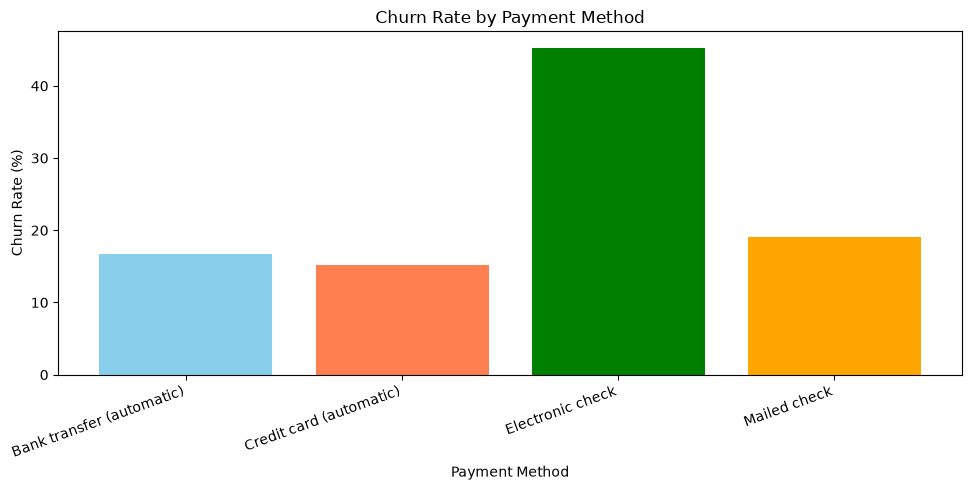

In [31]:

plt.figure(figsize=(10, 5))

plt.bar(
    payment_churn_rate.index,
    payment_churn_rate.values,
    color=["skyblue", "coral", "green", "orange"]
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.show()


In [32]:

internet_churn = df.groupby("InternetService")["Churn"].value_counts()

internet_churn


InternetService  Churn
DSL              No       1962
                 Yes       459
Fiber optic      No       1799
                 Yes      1297
No               No       1413
                 Yes       113
Name: count, dtype: int64

In [33]:

internet_churn_rate = df.groupby("InternetService")["Churn"].apply(
    lambda x: (x == "Yes").sum() / len(x) * 100
)

internet_churn_rate.round(2)


InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64

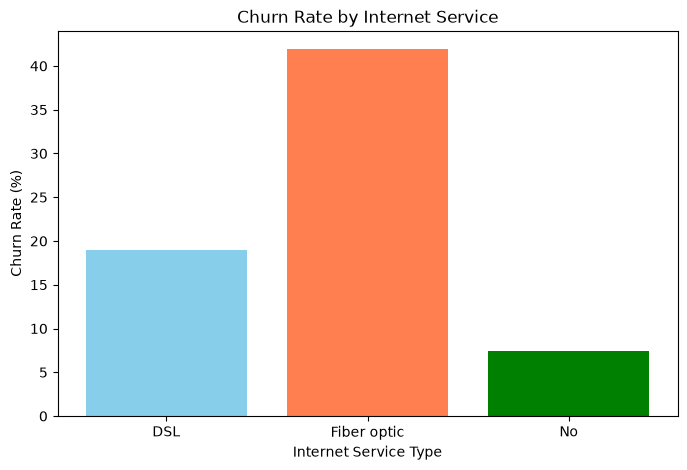

In [34]:

plt.figure(figsize=(8, 5))

plt.bar(
    internet_churn_rate.index,
    internet_churn_rate.values,
    color=["skyblue", "coral", "green"]
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service Type")
plt.ylabel("Churn Rate (%)")

plt.show()


In [35]:

eda_summary = pd.DataFrame({
    "Analysis": [
        "Contract Type",
        "Customer Tenure",
        "Monthly Charges",
        "Payment Method",
        "Internet Service"
    ],
    "Highest Churn Group": [
        contract_churn_rate.idxmax(),
        tenure_churn_rate.idxmax(),
        charges_churn_rate.idxmax(),
        payment_churn_rate.idxmax(),
        internet_churn_rate.idxmax()
    ],
    "Churn Rate (%)": [
        contract_churn_rate.max(),
        tenure_churn_rate.max(),
        charges_churn_rate.max(),
        payment_churn_rate.max(),
        internet_churn_rate.max()
    ]
})

eda_summary["Churn Rate (%)"] = eda_summary["Churn Rate (%)"].round(2)

eda_summary


,Analysis,Highest Churn Group,Churn Rate (%)
0,Contract Type,Month-to-month,42.71
1,Customer Tenure,0-12,47.44
2,Monthly Charges,61-90,33.91
3,Payment Method,Electronic check,45.29
4,Internet Service,Fiber optic,41.89


In [36]:

print("FINAL EDA SUMMARY")
print("-" * 50)

print(f"Overall Churn Rate: {(df['Churn'] == 'Yes').mean() * 100:.2f}%")

print("\nHighest Churn Groups:")
print(eda_summary.to_string(index=False))


FINAL EDA SUMMARY
--------------------------------------------------
Overall Churn Rate: 26.54%

Highest Churn Groups:
        Analysis Highest Churn Group  Churn Rate (%)
   Contract Type      Month-to-month           42.71
 Customer Tenure                0-12           47.44
 Monthly Charges               61-90           33.91
  Payment Method    Electronic check           45.29
Internet Service         Fiber optic           41.89


In [37]:

eda_summary.to_csv("../reports/eda_summary.csv", index=False)

print("EDA Summary saved successfully!")


EDA Summary saved successfully!
